# Proč dron letí: vztlak, hybnost a skutečná hustota vzduchu

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Proč dron letí](https://openskylab.space/edu_viz_why_drones_fly.html) · [English version](why_drones_fly_en.ipynb)

Vizuál vysvětluje vztlak profilu, pádový úhel, teorii hybnosti rotoru a nebezpečné režimy klesání. Tady teorii hybnosti použiješ na skutečné drony (DJI Mavic 3 Enterprise a Matrice 350 RTK) a na skutečnou hustotu vzduchu, kterou spočítáš z měřeného a modelovaného počasí na horách i v nížině.

**Cíl:** spočítat vztlak tenkého profilu a jeho mez, indukovanou rychlost a výkon při visení, ukázat, jak hustota vzduchu mění výdrž, a odhadnout rychlost klesání, při které hrozí vírový prstenec.

**Data:** hodinová teplota, tlak a vlhkost za posledních 92 dní z Open-Meteo pro Prahu, Sněžku a Lomnický štít; hmotnost, průměr vrtulí, baterie a výdrž dronů z technických listů DJI.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Dotaz na Open-Meteo; při chybě nebo vyčerpaném limitu to zkusí znovu."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo neodpovídá, spusť buňku za chvíli znovu.")

g = 9.81
# drony z technických listů DJI: hmotnost (kg), počet rotorů, průměr vrtule (m), energie baterií (Wh), max. doba visení (min)
DRONES = {
    "Mavic 3E":     dict(m=0.915, n=4, D=9.4 * 0.0254, E=77, hover_min=38),
    "Matrice 350":  dict(m=6.47,  n=4, D=21 * 0.0254,  E=2 * 263, hover_min=None),
}

## 2. Vztlak profilu a pád

Podle teorie tenkého profilu roste součinitel vztlaku lineárně s úhlem náběhu: c_L = 2π (α − α₀), kde α₀ ≈ −2 · prohnutí / hloubka (záporné pro prohnutý profil). Skutečný profil se ale při úhlu kolem 12–16° odtrhne a vztlak spadne. Vztlak L = ½ ρ v² S c_L.

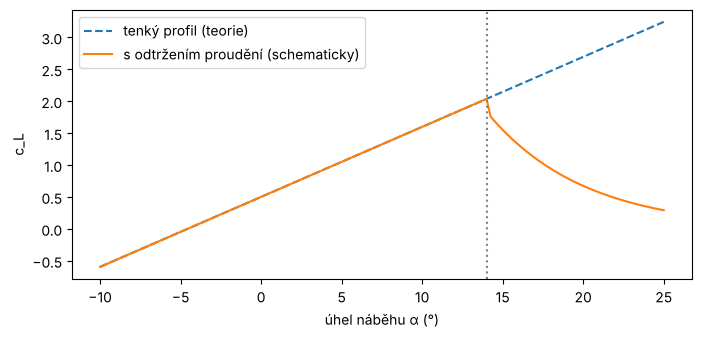

α =  0°: c_L = 0.50, vztlak  33.9 N (unese 3.46 kg)
α =  5°: c_L = 1.05, vztlak  70.9 N (unese 7.23 kg)
α = 10°: c_L = 1.60, vztlak 108.0 N (unese 11.00 kg)


In [2]:
camber = 0.04          # ◀ parametr: prohnutí profilu (podíl hloubky; 0 = souměrný, 0,04 = 4 %)
alpha_stall = 14       # ◀ parametr: pádový úhel (°), z měření skutečných profilů zhruba 12–16°
v, rho, S = 15, 1.2, 0.5     # rychlost (m/s), hustota (kg/m³), plocha křídla (m²): malý dron s pevným křídlem
alpha = np.linspace(-10, 25, 141)
a0 = -2 * camber
cl_theory = 2 * np.pi * (np.radians(alpha) - a0)
cl_real = np.where(alpha <= alpha_stall, cl_theory, 2 * np.pi * (np.radians(alpha_stall) - a0) * np.exp(-(alpha - alpha_stall) / 6) * 0.9)
plt.figure(figsize=(8, 3.5))
plt.plot(alpha, cl_theory, "--", label="tenký profil (teorie)"); plt.plot(alpha, cl_real, label="s odtržením proudění (schematicky)")
plt.axvline(alpha_stall, color="gray", ls=":"); plt.xlabel("úhel náběhu α (°)"); plt.ylabel("c_L"); plt.legend(); plt.show()
for a in (0, 5, 10):
    cl = 2 * np.pi * (np.radians(a) - a0)
    print(f"α = {a:2d}°: c_L = {cl:.2f}, vztlak {0.5 * rho * v**2 * S * cl:5.1f} N (unese {0.5 * rho * v**2 * S * cl / g:.2f} kg)")

> **✏️ Úkol 1.** Proč prohnutý profil nese i při úhlu náběhu 0° a souměrný ne? Nastav `camber = 0`. Při jakém úhlu by křídlo uneslo 2,5 kg? Proč teorie tenkého profilu nad pádovým úhlem neplatí a co se v tu chvíli děje s prouděním na horní straně? (Průběh za pádem je v grafu jen schematický.)

*Tvoje odpověď:* 

## 3. Dva pohledy na jednu sílu

Rotor při visení vrhá vzduch dolů. Teorie hybnosti: tah T = ṁ · w, kde w = 2 v_i je rychlost vzduchu daleko pod rotorem a ṁ = ρ A v_i hmotnostní tok diskem. Odtud v_i = √(T / (2 ρ A)). Tentýž tah je i rozdíl tlaků nad a pod diskem: Δp = T / A.

In [3]:
def hover(d, rho):
    T = d["m"] * g / d["n"]                 # tah jednoho rotoru (N)
    A = np.pi * d["D"] ** 2 / 4             # plocha disku (m²)
    vi = np.sqrt(T / (2 * rho * A))         # indukovaná rychlost (m/s)
    return dict(T=T, A=A, vi=vi, mdot=rho * A * vi, dp=T / A, P_ideal=d["n"] * T * vi)

rows = []
for name, d in DRONES.items():
    h = hover(d, 1.225)
    rows.append({"dron": name, "tah rotoru (N)": h["T"], "zatížení disku Δp (Pa)": h["dp"], "v_i (m/s)": h["vi"],
                 "ṁ (kg/s)": h["mdot"], "ṁ·2v_i (N)": h["mdot"] * 2 * h["vi"], "ideální výkon (W)": h["P_ideal"]})
pd.DataFrame(rows).set_index("dron").round(2)

,tah rotoru (N),zatížení disku Δp (Pa),v_i (m/s),ṁ (kg/s),ṁ·2v_i (N),ideální výkon (W)
dron,,,,,,
Mavic 3E,2.24,50.12,4.52,0.25,2.24,40.6
Matrice 350,15.87,71.01,5.38,1.47,15.87,341.7


> **✏️ Úkol 2.** Ověř, že sloupec ṁ · 2 v_i dává stejné číslo jako tah rotoru. Proč jsou rozdíl tlaků a hybnost vrženého vzduchu dva popisy téže síly, ne dvě síly, které se sčítají? Proč má Matrice 350 větší zatížení disku a vyšší indukovanou rychlost, i když má mnohem větší vrtule?

*Tvoje odpověď:* 

## 4. Skutečná hustota vzduchu: nížina, hory, léto a zima

Ideální výkon při visení je P = T^(3/2) / √(2 ρ A), tedy roste s 1/√ρ. Hustotu spočítáme z tlaku, teploty a vlhkosti za posledních 92 dní.

Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – zkusím znovu


Praha            208 m n. m.: ρ 1.120–1.257 kg/m³, medián 1.198


Sněžka          1587 m n. m.: ρ 0.986–1.090 kg/m³, medián 1.043


Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – zkusím znovu


Open-Meteo: SSLError – zkusím znovu


Open-Meteo: SSLError – zkusím znovu


Lomnický štít   2501 m n. m.: ρ 0.916–0.997 kg/m³, medián 0.957


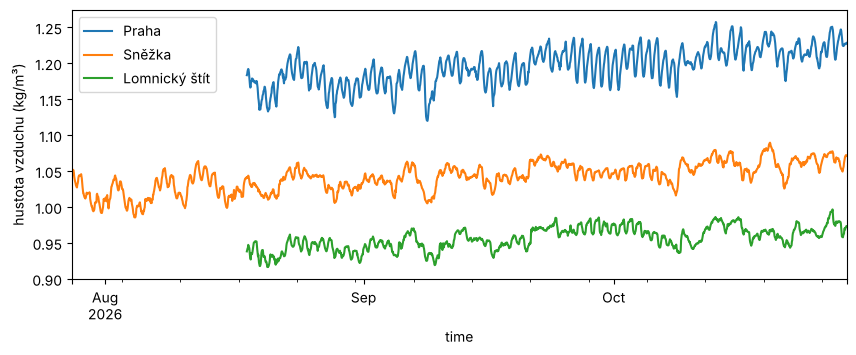

In [4]:
SITES = {"Praha": (50.08, 14.42), "Sněžka": (50.736, 15.740), "Lomnický štít": (49.195, 20.215)}
dens = {}
for name, (lat, lon) in SITES.items():
    w = open_meteo({"latitude": lat, "longitude": lon, "past_days": 92, "forecast_days": 1,
                    "hourly": "temperature_2m,relative_humidity_2m,surface_pressure", "timezone": "UTC"})
    df = pd.DataFrame(w["hourly"]).set_index("time")
    T = df.temperature_2m + 273.15
    e = df.relative_humidity_2m / 100 * 6.112 * np.exp(17.62 * df.temperature_2m / (243.12 + df.temperature_2m))
    Tv = T / (1 - 0.378 * e / df.surface_pressure)                    # virtuální teplota
    dens[name] = df.surface_pressure * 100 / (287.05 * Tv)
    print(f"{name:14s} {w['elevation']:5.0f} m n. m.: ρ {dens[name].min():.3f}–{dens[name].max():.3f} kg/m³, medián {dens[name].median():.3f}")
dens = pd.DataFrame(dens); dens.index = pd.to_datetime(dens.index)
ax = dens.plot(figsize=(10, 3.5)); ax.set(ylabel="hustota vzduchu (kg/m³)"); plt.show()

In [5]:
FM, eta = 0.60, 0.80     # ◀ parametr: účinnost rotoru (figure of merit) a účinnost motoru s regulátorem
d = DRONES["Mavic 3E"]
for name in dens:
    for label, rho_ in [("nejhustší", dens[name].max()), ("nejřidší", dens[name].min())]:
        P = hover(d, rho_)["P_ideal"] / (FM * eta)
        print(f"{name:14s} {label:9s} ρ = {rho_:.3f}: výkon {P:5.1f} W, visení {d['E'] / P * 60:4.1f} min")
print(f"výrobce udává max. dobu visení {d['hover_min']} min")

Praha          nejhustší ρ = 1.257: výkon  83.5 W, visení 55.3 min
Praha          nejřidší  ρ = 1.120: výkon  88.5 W, visení 52.2 min
Sněžka         nejhustší ρ = 1.090: výkon  89.7 W, visení 51.5 min
Sněžka         nejřidší  ρ = 0.986: výkon  94.3 W, visení 49.0 min
Lomnický štít  nejhustší ρ = 0.997: výkon  93.8 W, visení 49.3 min
Lomnický štít  nejřidší  ρ = 0.916: výkon  97.8 W, visení 47.2 min
výrobce udává max. dobu visení 38 min


> **✏️ Úkol 3.** O kolik procent je vzduch na Lomnickém štítu řidší než v Praze a o kolik procent víc výkonu potřebuje dron k visení? Ověř, že poměr výkonů je √(ρ_Praha / ρ_štít). Jaké FM a η by musely platit, aby odhad doby visení odpovídal údaji výrobce? Proč výrobce udává výdrž za ideálních podmínek?

*Tvoje odpověď:* 

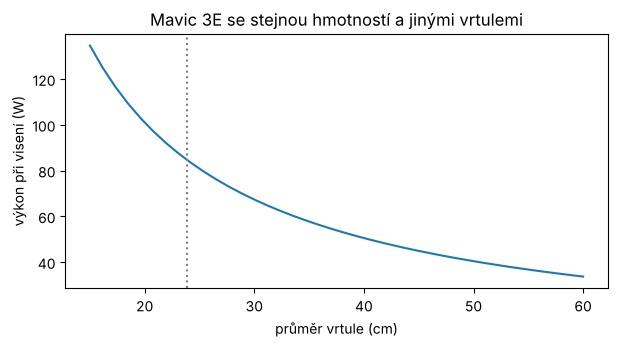

In [6]:
D_list = np.linspace(0.15, 0.6, 40)
P_D = [hover(dict(DRONES["Mavic 3E"], D=D_), 1.225)["P_ideal"] / (FM * eta) for D_ in D_list]
plt.figure(figsize=(7, 3.3)); plt.plot(D_list * 100, P_D); plt.axvline(DRONES["Mavic 3E"]["D"] * 100, color="gray", ls=":")
plt.xlabel("průměr vrtule (cm)"); plt.ylabel("výkon při visení (W)"); plt.title("Mavic 3E se stejnou hmotností a jinými vrtulemi"); plt.show()

> **✏️ Úkol 4.** Proč velké pomalé vrtule potřebují k visení méně výkonu než malé rychlé? Vysvětli to z P = T · v_i: kterou ze dvou veličin větší disk mění? Proč přesto nemá malý dron obří vrtule?

*Tvoje odpověď:* 

## 5. Klesání a vírový prstenec

Když dron klesá svisle rychlostí srovnatelnou s indukovanou rychlostí při visení v_h, vzduch, který rotor tlačí dolů, se mu vrací shora skrz disk. Podle Leishmana (2006) je oblast vírového prstence zhruba mezi 0,5 v_h a 1,5 v_h (přesná mez závisí na měření).

In [7]:
v_desc = {"Mavic 3E": 6, "Matrice 350": 7}          # max. rychlost klesání z technických listů (m/s)
site = "Sněžka"                                       # ◀ parametr: místo (hustota = medián za 92 dní)
for name, d in DRONES.items():
    vh = hover(d, dens[site].median())["vi"]
    print(f"{name:12s}: v_h = {vh:.1f} m/s → vírový prstenec zhruba {0.5 * vh:.1f}–{1.5 * vh:.1f} m/s, "
          f"max. klesání výrobce {v_desc[name]} m/s ({v_desc[name] / vh:.1f} v_h)")

Mavic 3E    : v_h = 4.9 m/s → vírový prstenec zhruba 2.5–7.4 m/s, max. klesání výrobce 6 m/s (1.2 v_h)
Matrice 350 : v_h = 5.8 m/s → vírový prstenec zhruba 2.9–8.8 m/s, max. klesání výrobce 7 m/s (1.2 v_h)


> **✏️ Úkol 5.** Při jaké svislé rychlosti klesání hrozí vírový prstenec u Mavicu a u Matrice? Leží maximální rychlost klesání od výrobce v této oblasti? Proč je bezpečnější klesat šikmo nebo s dopřednou rychlostí a proč je nebezpečné rychlé svislé klesání těsně nad zemí, kdy už není prostor na vybrání?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Počasí: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- DJI Mavic 3 Enterprise (3E): vzletová hmotnost 915 g, vrtule 9453F (9,4″), baterie 77 Wh, max. doba visení 38 min, max. rychlost klesání 6 m/s; DJI Matrice 350 RTK: hmotnost s bateriemi TB65 6,47 kg, max. vzletová 9,2 kg, vrtule 21″, 2 × 263 Wh, max. rychlost klesání 7 m/s (technické listy DJI).
- Leishman, J. G. (2006). *Principles of Helicopter Aerodynamics*, 2. vyd. Cambridge University Press (teorie hybnosti, účinnost FM, vírový prstenec).
- Anderson, J. D. (2017). *Fundamentals of Aerodynamics*, 6. vyd. McGraw-Hill (teorie tenkého profilu).
- Hustota vlhkého vzduchu přes virtuální teplotu; tlak nasycených par Magnusovým vzorcem (WMO-No. 8, 2018).

### Jak citovat

OpenSkyLab (2026). Proč dron letí: vztlak, hybnost a skutečná hustota vzduchu [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*